# Comparing the trained models

This notebook puts the Milestone 3 models next to the Milestone 2 strong baseline, on the same test set (1,000 posts, identical to the SemEval-2023 test set):

| System | Size | Spoiler | Type |
|---|---|---|---|
| RoBERTa-base QA (Milestone 2 strong baseline) | 125M | extracts spans | RoBERTa-base classifier |
| DeBERTa-v3-large QA (`1-deberta-qa.ipynb`) | 435M | extracts spans | same classifier |
| Flan-T5-large (`2-flan-t5.ipynb`) | 783M | generates text | generated by the model |
| Llama-3.1-8B-Instruct, QLoRA (`3-llama-qlora.ipynb`) | 8B (42M trained) | generates text | generated by the model |

It only reads files the other notebooks wrote (`output/`, and `inputs/milestone2/` for the baseline), so it takes seconds and can be re-run any time. A model whose notebook hasn't been run yet is left out.

What it produces:
1. the **main results table** (overall and per-type BLEU, METEOR, BERTScore, type balanced accuracy, and BLEU with gold types);
2. the **learning-rate sweeps** of all models side by side;
3. a **paired bootstrap test**: is each model's BLEU difference to the strong baseline bigger than chance?
4. a **chart** of BLEU per spoiler type;
5. the **type predictions** compared;
6. **where the errors are**: wrong types, posts that score zero, and whether the generated spoilers are copied from the article;
7. a few posts where the best model and the baseline disagree most.

Run it with `jupyter nbconvert --to notebook --execute --inplace 4-compare.ipynb` (or `SMOKE=1 ... --output smoke-run.ipynb` to compare the smoke-test outputs). Tables go to `output/comparison-*.csv` and `.md`, the chart to `output/figures/`.

## Setup

Imports, paths, and the list of systems with where their files are.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from spoilerqa.data import DEFAULT_DATA_DIR, TYPES, load_jsonl, load_split, post_text, spoiler_type
from spoilerqa.metrics import as_text, bleu_scores, ensure_nltk_data

ensure_nltk_data()
pd.set_option("display.max_colwidth", 80)

SMOKE = os.environ.get("SMOKE", "0") == "1"
DATA_DIR = Path(os.environ.get("DATA_DIR", DEFAULT_DATA_DIR))
OUTPUT_DIR = Path("smoke/output") if SMOKE else Path("output")
M2_DIR = Path("inputs/milestone2")
(OUTPUT_DIR / "figures").mkdir(parents=True, exist_ok=True)

SYSTEMS = [
    {"key": "roberta-base-qa", "label": "RoBERTa-base QA (M2 baseline)", "short": "RoBERTa-base QA", "size": "125M",
     "types": "M2 classifier", "dir": M2_DIR, "stem": "strong-baseline"},
    {"key": "deberta-qa", "label": "DeBERTa-v3-large QA", "short": "DeBERTa-v3-large QA", "size": "435M",
     "types": "M2 classifier", "dir": OUTPUT_DIR, "stem": "deberta-qa"},
    {"key": "flan-t5", "label": "Flan-T5-large", "short": "Flan-T5-large", "size": "783M",
     "types": "generated", "dir": OUTPUT_DIR, "stem": "flan-t5"},
    {"key": "llama-qlora", "label": "Llama-3.1-8B QLoRA", "short": "Llama-3.1-8B QLoRA", "size": "8B (42M trained)",
     "types": "generated", "dir": OUTPUT_DIR, "stem": "llama-qlora"},
]


def score_file(system, name):
    return system["dir"] / "scores" / f"{system['stem']}-{name}.json"


available = [s for s in SYSTEMS if score_file(s, "test").exists()]
missing = [s["label"] for s in SYSTEMS if s not in available]
print("systems with test scores:", [s["label"] for s in available])
print("not run yet:", missing or "none")

systems with test scores: ['RoBERTa-base QA (M2 baseline)', 'DeBERTa-v3-large QA', 'Flan-T5-large', 'Llama-3.1-8B QLoRA']
not run yet: none


## 1. Main results (test)

One row per system, from the `score.py` JSON files.
- **BLEU** is the main metric, overall and per gold type.
- **BLEU (gold types)** is the same model when the spoiler type is given. The gap to BLEU shows how much wrong types cost.
- The reference rows are from the SemEval-2023 overview paper.

In [2]:
def load_scores(system, name):
    path = score_file(system, name)
    return json.loads(path.read_text()) if path.exists() else None


rows = []
for s in available:
    test_scores, gold_scores = load_scores(s, "test"), load_scores(s, "goldtypes-test")
    sp = test_scores["spoiler"]
    rows.append({
        "system": s["label"], "size": s["size"], "types": s["types"],
        "BLEU": sp["all"]["bleu"], "phrase": sp["phrase"]["bleu"], "passage": sp["passage"]["bleu"],
        "multi": sp["multi"]["bleu"], "METEOR": sp["all"].get("meteor"), "BERTScore": sp["all"].get("bertscore"),
        "type bal. acc.": test_scores.get("type", {}).get("balanced-accuracy"),
        "BLEU (gold types)": gold_scores["spoiler"]["all"]["bleu"] if gold_scores else None,
    })
main = pd.DataFrame(rows)
reference = pd.DataFrame([
    {"system": "Reference: SemEval organizer baseline (DeBERTa-large QA)", "BLEU": 0.40, "phrase": 0.65,
     "passage": 0.24, "multi": 0.12},
    {"system": "Reference: best SemEval-2023 system", "BLEU": 0.48, "phrase": 0.66, "passage": 0.32, "multi": 0.44,
     "type bal. acc.": 0.74},
])
main_with_refs = pd.concat([main, reference], ignore_index=True)


def to_markdown(df, digits=4):
    # A plain markdown table (no extra dependency), for pasting into the report notes.
    def fmt(v):
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return ""
        return f"{v:.{digits}f}" if isinstance(v, float) else str(v)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines) + "\n"


main_with_refs.to_csv(OUTPUT_DIR / "comparison-test.csv", index=False)
(OUTPUT_DIR / "comparison-test.md").write_text(to_markdown(main_with_refs))
main_with_refs.style.format(precision=4, na_rep="")

,system,size,types,BLEU,phrase,passage,multi,METEOR,BERTScore,type bal. acc.,BLEU (gold types)
0,RoBERTa-base QA (M2 baseline),125M,M2 classifier,0.3843,0.5704,0.2219,0.3080,0.4182,0.9140,0.6920,0.4091
1,DeBERTa-v3-large QA,435M,M2 classifier,0.4377,0.6026,0.2925,0.3731,0.4885,0.9234,0.6920,0.4818
2,Flan-T5-large,783M,generated,0.4621,0.5955,0.3346,0.4332,0.4252,0.9253,0.7473,0.5141
3,Llama-3.1-8B QLoRA,8B (42M trained),generated,0.5071,0.6481,0.3659,0.4911,0.5079,0.9337,0.7585,0.5607
4,Reference: SemEval organizer baseline (DeBERTa-large QA),,,0.4000,0.6500,0.2400,0.1200,,,,
5,Reference: best SemEval-2023 system,,,0.4800,0.6600,0.3200,0.4400,,,0.7400,


## 2. Learning-rate sweeps (dev)

The parameter sweep for every model: best dev BLEU for each learning rate, the epoch it came from, and the training time.
- The **QA models'** dev BLEU is decoded with **gold types**, as in Milestone 2.
- The **generative models'** dev BLEU is **end to end** (they write their own type).
- So compare learning rates within a model, not dev numbers across model families; the test table above is the fair comparison.

In [3]:
def load_sweep(system):
    name = "qa-sweep.json" if system["key"] == "roberta-base-qa" else f"{system['stem']}-sweep.json"
    path = system["dir"] / name
    return json.loads(path.read_text()) if path.exists() else []


sweep_rows = []
for s in SYSTEMS:
    for run in load_sweep(s):
        per_epoch = run["dev_bleu_per_epoch"]
        sweep_rows.append({
            "system": s["label"], "learning rate": f"{run['learning_rate']:g}",
            "best dev BLEU": max(per_epoch), "best epoch": int(np.argmax(per_epoch)) + 1,
            "dev BLEU per epoch": " / ".join(f"{b:.3f}" for b in per_epoch),
            "dev decoded with": "gold types" if s["types"] == "M2 classifier" else "own types",
            "train minutes": run.get("train_minutes", 8.6 if s["key"] == "roberta-base-qa" else None),
        })
sweeps = pd.DataFrame(sweep_rows)
sweeps.to_csv(OUTPUT_DIR / "comparison-sweep.csv", index=False)
(OUTPUT_DIR / "comparison-sweep.md").write_text(to_markdown(sweeps))
sweeps.style.format(precision=4, na_rep="")

,system,learning rate,best dev BLEU,best epoch,dev BLEU per epoch,dev decoded with,train minutes
0,RoBERTa-base QA (M2 baseline),1e-05,0.4434,2,0.412 / 0.443 / 0.435,gold types,8.6000
1,RoBERTa-base QA (M2 baseline),3e-05,0.4432,3,0.418 / 0.429 / 0.443,gold types,8.6000
2,RoBERTa-base QA (M2 baseline),5e-05,0.4272,2,0.419 / 0.427 / 0.421,gold types,8.6000
3,DeBERTa-v3-large QA,5e-06,0.4857,3,0.468 / 0.481 / 0.486,gold types,66.0000
4,DeBERTa-v3-large QA,1e-05,0.4964,3,0.473 / 0.483 / 0.496,gold types,66.0000
5,DeBERTa-v3-large QA,2e-05,0.4887,3,0.476 / 0.488 / 0.489,gold types,66.0000
6,Flan-T5-large,5e-05,0.4157,4,0.262 / 0.329 / 0.345 / 0.416 / 0.411,own types,170.6000
7,Flan-T5-large,0.0001,0.4262,5,0.274 / 0.358 / 0.408 / 0.424 / 0.426,own types,165.9000
8,Flan-T5-large,0.0003,0.4505,5,0.333 / 0.362 / 0.425 / 0.443 / 0.450,own types,167.6000
9,Llama-3.1-8B QLoRA,5e-05,0.4905,2,0.475 / 0.490,own types,241.5000


## 3. Is the difference real? Paired bootstrap

The test set has 1,000 posts, so a BLEU difference of a point or two could be luck. For each model we compare its per-post BLEU with the strong baseline's on the **same** posts:
1. Resample the 1,000 posts with replacement 10,000 times.
2. Each time, recompute the mean BLEU difference.

The table gives the observed difference, its 95% interval, and *p*, the share of resamples in which the model is not better than the baseline. If the interval excludes 0, the difference is unlikely to be chance. The test is run overall and within each gold type.

In [4]:
gold = {r["uuid"]: r for r in load_split(DATA_DIR, "test")}


def per_post_bleu(system):
    preds = {p["uuid"]: p for p in load_jsonl(system["dir"] / f"{system['stem']}-test.jsonl")}
    uuids = [u for u in gold if u in preds]
    scores = bleu_scores([as_text(gold[u]["spoiler"]) for u in uuids], [as_text(preds[u]["spoiler"]) for u in uuids])
    return pd.Series(scores, index=uuids)


post_bleu = {s["key"]: per_post_bleu(s) for s in available}
baseline = post_bleu["roberta-base-qa"]
rng = np.random.default_rng(0)
boot_rows = []
for s in available[1:]:
    common = baseline.index.intersection(post_bleu[s["key"]].index)
    for subset in ["all"] + TYPES:
        idx = [u for u in common if subset == "all" or spoiler_type(gold[u]) == subset]
        if len(idx) < 2:
            continue
        diff = post_bleu[s["key"]][idx].to_numpy() - baseline[idx].to_numpy()
        samples = rng.integers(0, len(diff), size=(10_000, len(diff)))
        means = diff[samples].mean(axis=1)
        boot_rows.append({"system": s["label"], "posts": subset, "n": len(idx),
                          "BLEU difference vs baseline": diff.mean(), "95% low": np.percentile(means, 2.5),
                          "95% high": np.percentile(means, 97.5), "p (not better)": float((means <= 0).mean())})
bootstrap = pd.DataFrame(boot_rows)
if len(bootstrap):
    bootstrap.to_csv(OUTPUT_DIR / "comparison-bootstrap.csv", index=False)
    (OUTPUT_DIR / "comparison-bootstrap.md").write_text(to_markdown(bootstrap))
    display(bootstrap.style.format(precision=4))
else:
    print("no Milestone 3 model has test predictions yet")

,system,posts,n,BLEU difference vs baseline,95% low,95% high,p (not better)
0,DeBERTa-v3-large QA,all,1000,0.0534,0.0307,0.0755,0.0000
1,DeBERTa-v3-large QA,phrase,423,0.0322,-0.0044,0.0696,0.0445
2,DeBERTa-v3-large QA,passage,403,0.0706,0.0336,0.1078,0.0001
3,DeBERTa-v3-large QA,multi,174,0.0651,0.0326,0.0986,0.0000
4,Flan-T5-large,all,1000,0.0778,0.0521,0.1042,0.0000
5,Flan-T5-large,phrase,423,0.0250,-0.0159,0.0657,0.1170
6,Flan-T5-large,passage,403,0.1127,0.0712,0.1558,0.0000
7,Flan-T5-large,multi,174,0.1252,0.0730,0.1770,0.0000
8,Llama-3.1-8B QLoRA,all,1000,0.1228,0.0964,0.1487,0.0000
9,Llama-3.1-8B QLoRA,phrase,423,0.0777,0.0374,0.1186,0.0002


## 4. BLEU per spoiler type

The same numbers as the main table, drawn per gold type. Bars for the same system share a color in every group, and the overall score is labeled. The chart is saved to `output/figures/bleu-by-type.png` for the slides.

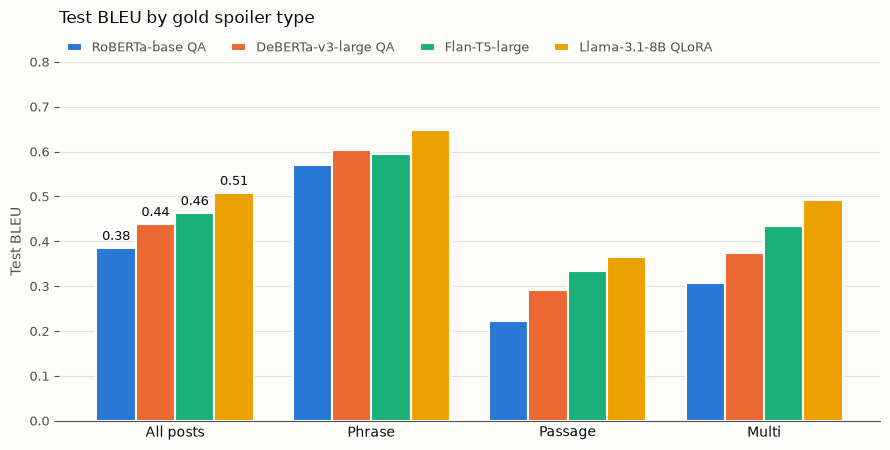

In [5]:
# Colors: the first four slots of a color-blind-checked categorical palette, always in this order, so each
# system keeps its color whichever models are present. Text stays in neutral ink.
SERIES_COLORS = {"roberta-base-qa": "#2a78d6", "deberta-qa": "#eb6834", "flan-t5": "#1baf7a", "llama-qlora": "#eda100"}
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"

groups = ["all", "phrase", "passage", "multi"]
group_labels = ["All posts", "Phrase", "Passage", "Multi"]
fig, ax = plt.subplots(figsize=(9, 4.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
width = 0.8 / max(len(available), 1)
for j, s in enumerate(available):
    values = [load_scores(s, "test")["spoiler"][g]["bleu"] for g in groups]
    x = np.arange(len(groups)) + (j - (len(available) - 1) / 2) * width
    ax.bar(x, values, width, color=SERIES_COLORS[s["key"]], edgecolor=SURFACE, linewidth=1.5, label=s["short"], zorder=2)
    ax.text(x[0], values[0] + 0.012, f"{values[0]:.2f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(np.arange(len(groups)), group_labels, color=INK, fontsize=10)
ax.set_ylabel("Test BLEU", color=INK_2)
ax.set_ylim(0, 0.8)
ax.tick_params(axis="y", colors=INK_2, labelsize=9)
ax.tick_params(axis="x", length=0)
ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(INK_2)
ax.set_title("Test BLEU by gold spoiler type", loc="left", color=INK, fontsize=12, pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(available), frameon=False, fontsize=9,
          labelcolor=INK_2, handlelength=1.2, borderaxespad=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "figures" / "bleu-by-type.png", dpi=200, facecolor=SURFACE)
plt.show()

## 5. Spoiler types: classifier vs generated

The QA systems take their types from the Milestone 2 RoBERTa classifier. Flan-T5 and Llama write the type themselves. This table compares the type predictions on test: balanced accuracy, and recall per gold type (how often a post of that type gets the right label).

In [6]:
type_rows = []
for s in available:
    t = load_scores(s, "test").get("type")
    if t is None or (s["types"] == "M2 classifier" and s["key"] != "roberta-base-qa"):
        continue  # the DeBERTa row would repeat the classifier
    type_rows.append({"types from": "RoBERTa-base classifier (M2)" if s["types"] == "M2 classifier" else s["label"],
                      "balanced accuracy": t["balanced-accuracy"],
                      **{f"recall {label}": t[f"recall-{label}"] for label in TYPES}})
pd.DataFrame(type_rows).style.format(precision=4)

,types from,balanced accuracy,recall phrase,recall passage,recall multi
0,RoBERTa-base classifier (M2),0.6920,0.6998,0.7097,0.6667
1,Flan-T5-large,0.7473,0.7470,0.8511,0.6437
2,Llama-3.1-8B QLoRA,0.7585,0.7967,0.7891,0.6897


## 6. Where the errors are

A few counts per system on the test set:
- **wrong type**: posts whose predicted type differs from the gold type (out of 1,000);
- **zero BLEU**: the share of posts, per gold type, whose spoiler shares no words with the gold one, i.e. a complete miss;
- **copied from the article**: the share of predicted spoiler items that appear word for word in the article (ignoring case and spacing). The QA models copy by construction; for the generative models this shows how often they paraphrase or make text up;
- **items per multi prediction**: how many spoilers the system gives when it predicts *multi*. The QA systems always give the number tuned on dev; the generative models decide per post.

Written to `output/comparison-errors.csv` and `.md`.

In [7]:
from collections import Counter

from spoilerqa.data import build_context


def squash(text):
    return " ".join(text.split()).lower()


error_rows = []
for s in available:
    preds = {p["uuid"]: p for p in load_jsonl(s["dir"] / f"{s['stem']}-test.jsonl")}
    uuids = [u for u in gold if u in preds]
    scores = post_bleu[s["key"]]
    row = {"system": s["label"],
           "wrong type": sum(preds[u].get("spoilerType") != spoiler_type(gold[u]) for u in uuids)}
    for t in TYPES:
        of_type = [u for u in uuids if spoiler_type(gold[u]) == t]
        row[f"zero BLEU {t}"] = float((scores[of_type] == 0).mean())
    row["zero BLEU all"] = float((scores[uuids] == 0).mean())
    items = copied = 0
    multi_counts = Counter()
    for u in uuids:
        spans = preds[u]["spoiler"] if isinstance(preds[u]["spoiler"], list) else [preds[u]["spoiler"]]
        context = squash(build_context(gold[u]))
        items += len(spans)
        copied += sum(bool(squash(x)) and squash(x) in context for x in spans)
        if preds[u].get("spoilerType") == "multi":
            multi_counts[len(spans)] += 1
    row["copied from the article"] = copied / items
    row["items per multi prediction"] = ", ".join(f"{k}: {v}" for k, v in sorted(multi_counts.items()))
    error_rows.append(row)
errors = pd.DataFrame(error_rows)
errors.to_csv(OUTPUT_DIR / "comparison-errors.csv", index=False)
(OUTPUT_DIR / "comparison-errors.md").write_text(to_markdown(errors, digits=3))
errors.style.format(precision=3)

,system,wrong type,zero BLEU phrase,zero BLEU passage,zero BLEU multi,zero BLEU all,copied from the article,items per multi prediction
0,RoBERTa-base QA (M2 baseline),302,0.161,0.218,0.075,0.169,1.000,5: 205
1,DeBERTa-v3-large QA,302,0.147,0.169,0.040,0.137,1.000,5: 205
2,Flan-T5-large,229,0.170,0.136,0.052,0.136,0.936,"1: 2, 2: 29, 3: 17, 4: 12, 5: 55, 6: 14, 7: 5, 8: 2, 11: 1"
3,Llama-3.1-8B QLoRA,225,0.135,0.122,0.029,0.111,0.989,"1: 2, 2: 45, 3: 15, 4: 11, 5: 80, 10: 1"


## 7. Where the best model and the baseline disagree

The test posts where the model with the best test BLEU gains or loses the most against the strong baseline. These are a starting point for the per-type error analysis in the final report.

In [8]:
if len(available) > 1:
    best = max(available[1:], key=lambda s: load_scores(s, "test")["spoiler"]["all"]["bleu"])
    best_preds = {p["uuid"]: p for p in load_jsonl(best["dir"] / f"{best['stem']}-test.jsonl")}
    base_preds = {p["uuid"]: p for p in load_jsonl(M2_DIR / "strong-baseline-test.jsonl")}
    common = baseline.index.intersection(post_bleu[best["key"]].index)
    delta = (post_bleu[best["key"]][common] - baseline[common]).sort_values()
    picks = list(delta.index[-4:][::-1]) + list(delta.index[:4])
    print("best model on test:", best["label"])
    display(pd.DataFrame([{
        "post": post_text(gold[u]), "gold type": spoiler_type(gold[u]), "gold spoiler": as_text(gold[u]["spoiler"]),
        "baseline": as_text(base_preds[u]["spoiler"]), best["short"]: as_text(best_preds[u]["spoiler"]),
        "BLEU change": round(float(delta[u]), 3),
    } for u in picks]))
else:
    print("no Milestone 3 model has test predictions yet")

best model on test: Llama-3.1-8B QLoRA


,post,gold type,gold spoiler,baseline,Llama-3.1-8B QLoRA,BLEU change
0,Son of alleged mugger returns stolen money to victim gets an AWESOME surprise,passage,she immediately returned the cash to Lunsford.,Christian Lunsford,she immediately returned the cash to Lunsford,1.0
1,Is this proof that Robin Thicke has officially moved on?,passage,Model April Love Geary has been snapping selfies all over Robin Thicke's Los...,Life goes on,Model April Love Geary has been snapping selfies all over Robin Thicke's Los...,1.0
2,Outcast star 'Patrick Fugit' has a better Dungeons &amp; Dragons name than you,phrase,Bandy Swiftpet,Philip Glenister,Bandy Swiftpet,1.0
3,21 Celebs who you didn't know were transgender!,multi,Candis Cayne Amanda Lepore Chaz Bono Laverne Cox Thomas Beatie,Lana Wachowski Erika Ervin Jamie Clayton Hari Nef Valentijn De Hingh,Candis Cayne Amanda Lepore Chaz Bono Laverne Cox Thomas Beatie,1.0
4,New Galaxy S8 Leak Reveals Samsung's Powerful Surprise,phrase,VR,VR,ARM’s Mali-G71,-1.0
5,Here’s how you can get free Pokecoins in Pokemon Go,passage,All you need is to be above level 5 and have one of your Pokemon assigned to...,All you need is to be above level 5 and have one of your Pokemon assigned to...,"While your Pokemon defends a gym controlled by your team, you earn free dail...",-1.0
6,Here’s How Many Black People Have Been Killed By Police Since Colin Kaeperni...,phrase,15,15,67 people,-1.0
7,@Ricky_Martin has a message for kids everywhere,phrase,dream big,dream big,I hope this book inspires young readers to believe that dreams woven from th...,-1.0
